# Modèle de fréquence avec XGBoost

**Objectif** : construire le meilleur modèle de fréquence possible avec XGBoost, et le comparer à la régression logistique **E** du notebook 01 (17 variables choisies par logique métier).

**Barre à battre** (logistique E, hors pli sur les 50 000 contrats) : log-loss **0,21357** ; RMSE de la prime **541,7941** (avec la gravité Gamma + courbes).

**Protocole**, identique à celui de la logistique :
- **mêmes 5 paquets par client** des 50 000 contrats que les notebooks 01 et 03 ; le paquet 1 est le jeu de validation du notebook 01 ;
- chaque contrat est prédit par un modèle qui ne l'a pas vu ;
- **tous les choix** (réglages, nombre d'arbres, poids du mélange, recalibration) sont faits sur les **paquets 2 à 5 seulement**. Le paquet 1 sert de contrôle honnête ;
- mesures : log-loss, Gini et Brier pour la fréquence ; RMSE de la prime (probabilité × gravité hors pli du binôme) pour la mesure Kaggle ;
- test « deux erreurs-types » sur l'écart paquet par paquet, comme dans le notebook 01.

Ce notebook lit les probabilités de la logistique E produites par le notebook 01 (`Data/predictions/frequence_final_*.csv`).

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from joblib import Parallel, delayed
import xgboost as xgb
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "Data" / "train.csv").exists())
PREDICTIONS = RACINE / "Data" / "predictions"
SEED = 42

train = pd.read_csv(RACINE / "Data" / "train.csv", dtype={"code_postal": str})
test = pd.read_csv(RACINE / "Data" / "test.csv", dtype={"code_postal": str})
y = train["nombre_sinistres"]
groupes = train["id_client"]

# Les 5 paquets par client des 50 000 contrats (identiques aux notebooks 01 et 03 ; le paquet 1 est la validation)
decoupage = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
plis_50k = list(decoupage.split(train, y, groups=groupes))
pli = np.zeros(len(train), dtype=int)
for k, (_, pos_eval) in enumerate(plis_50k, 1):
    pli[pos_eval] = k
binome = pd.read_csv(PREDICTIONS / "binome_composantes_oof_train.csv")
logistique_E = pd.read_csv(PREDICTIONS / "frequence_final_oof_train.csv")
assert (binome["pli"].values == pli).all() and (logistique_E["pli"].values == pli).all()

gravite, montant = binome["gravite_gamma_courbes"].values, binome["montant_sinistre"].values
p_E, p_binome = logistique_E["proba_pred"].values, binome["proba_logistique_courbes"].values
choix = pli != 1   # paquets 2 à 5 : les seuls utilisés pour choisir


def evaluer(y_vrai, proba):
    return {"log-loss": log_loss(y_vrai, proba), "Brier": brier_score_loss(y_vrai, proba),
            "Gini": 2 * roc_auc_score(y_vrai, proba) - 1}


def logloss_plis(p):
    return np.array([log_loss(y[pli == k], p[pli == k]) for k in range(1, 6)])


def rmse_plis(p):
    return np.array([np.sqrt(np.mean((p[pli == k] * gravite[pli == k] - montant[pli == k]) ** 2)) for k in range(1, 6)])


def verdict(ecarts):
    # Test des deux erreurs-types sur l'écart paquet par paquet (négatif = mieux)
    seuil = 2 * ecarts.std() / np.sqrt(len(ecarts))
    return "égal" if abs(ecarts.mean()) <= seuil else ("mieux" if ecarts.mean() < 0 else "pire")


def ligne(nom, p):
    # Toutes les mesures d'une fréquence hors pli, comparée à la logistique E et au binôme
    ll, r = logloss_plis(p), rmse_plis(p)
    return {"modèle": nom, "log-loss": log_loss(y, p), "log-loss paquets 2-5": ll[1:].mean(), "log-loss paquet 1": ll[0],
            "Gini": 2 * roc_auc_score(y, p) - 1, "Brier": brier_score_loss(y, p),
            "RMSE prime": np.sqrt(np.mean((p * gravite - montant) ** 2)), "RMSE prime paquet 1": r[0],
            "log-loss vs E": (ll - logloss_plis(p_E)).mean(), "verdict log-loss vs E": verdict(ll - logloss_plis(p_E)),
            "prime vs E": (r - rmse_plis(p_E)).mean(), "verdict prime vs E": verdict(r - rmse_plis(p_E)),
            "prime vs binôme": (r - rmse_plis(p_binome)).mean(), "verdict prime vs binôme": verdict(r - rmse_plis(p_binome)),
            "sinistres prédits": p.sum()}


print("Contrats :", len(train), "| sinistres observés :", int(y.sum()), "| paquets identiques aux notebooks 01 et 03 : oui")
print(f"Logistique E : log-loss {log_loss(y, p_E):.5f} | RMSE prime {np.sqrt(np.mean((p_E * gravite - montant) ** 2)):.4f}")

Contrats : 50000 | sinistres observés : 2917 | paquets identiques aux notebooks 01 et 03 : oui
Logistique E : log-loss 0.21357 | RMSE prime 541.7941


## 1. Préparation des données pour les arbres

Un arbre coupe les variables en seuils : l'échelle ne compte pas, et il trouve seul les effets non linéaires et les interactions. La préparation est donc plus légère que pour la logistique :

| Traitement | Pourquoi |
|---|---|
| Les 15 variables numériques **brutes**, sans logarithme ni standardisation | inutile pour un arbre |
| Poids et cylindrée à 0 → manquant ; âge et permis du 2ᵉ conducteur → manquant s'il n'y en a pas | XGBoost sait gérer les valeurs manquantes |
| 5 variables calculées : puissance / poids, prix par cheval, âge au permis, jeune 2ᵉ conducteur, 2ᵉ conducteur novice | des rapports que les arbres trouvent mal seuls |
| 7 catégorielles à peu de modalités en **catégories natives** de XGBoost (modalité inconnue → manquant) | pas besoin de one-hot |
| Marque, modèle, département et commune : **taux de sinistres lissé** ($m$ = 300), calculé hors pli par client, + **effectif** de la modalité | jamais les 886 modèles ou 12 800 communes bruts, que les arbres apprendraient par cœur |

Toute la préparation est apprise sur les 4 paquets d'apprentissage de chaque découpage.

In [2]:
FAIBLES = ["type_contrat", "freq_paiement", "paiement", "utilisation", "conducteur2", "essence_vehicule", "type_vehicule"]
FORTES = ["marque_vehicule", "modele_vehicule", "departement", "code_postal"]
NUMERIQUES = ["bonus", "duree_contrat", "anciennete_info", "age_conducteur1", "age_conducteur2", "anciennete_permis1",
              "anciennete_permis2", "anciennete_vehicule", "cylindre_vehicule", "din_vehicule", "debut_vente_vehicule",
              "fin_vente_vehicule", "vitesse_vehicule", "prix_vehicule", "poids_vehicule"]


def nettoyer_arbre(X):
    # Nettoyage fixe : valeurs impossibles -> manquant, département, variables calculées
    X = X.copy()
    X["poids_vehicule"] = X["poids_vehicule"].replace(0, np.nan)
    X["cylindre_vehicule"] = X["cylindre_vehicule"].replace(0, np.nan)
    sans_c2 = X["conducteur2"] == "No"
    X.loc[sans_c2, ["age_conducteur2", "anciennete_permis2"]] = np.nan   # pas de 2e conducteur : manquant, pas 0
    X["departement"] = X["code_postal"].str[:2]
    X["puissance_poids"] = X["din_vehicule"] / X["poids_vehicule"]
    X["prix_par_cheval"] = X["prix_vehicule"] / X["din_vehicule"]
    X["age_permis1"] = X["age_conducteur1"] - X["anciennete_permis1"]
    X["jeune_conducteur2"] = ((~sans_c2) & (X["age_conducteur2"] < 26)).astype(int)
    X["novice2"] = ((~sans_c2) & (X["anciennete_permis2"] < 3)).astype(int)
    return X


CALCULEES = ["puissance_poids", "prix_par_cheval", "age_permis1", "jeune_conducteur2", "novice2"]


def taux_lisse(cle_appr, y_appr, cle_cible, lissage):
    stats = y_appr.groupby(cle_appr).agg(["sum", "count"])
    taux = (stats["sum"] + lissage * y_appr.mean()) / (stats["count"] + lissage)
    return cle_cible.map(taux).astype(float).fillna(y_appr.mean())


def preparer_arbre(X_appr, y_appr, groupes_appr, X_eval, lissage=300):
    # Prépare le tableau pour XGBoost, appris sur X_appr seulement
    A, B = nettoyer_arbre(X_appr), nettoyer_arbre(X_eval)
    sortie_A, sortie_B = A[NUMERIQUES + CALCULEES].copy(), B[NUMERIQUES + CALCULEES].copy()
    # Peu de modalités : catégories natives de XGBoost (modalité inconnue -> manquant)
    for col in FAIBLES:
        modalites = sorted(A[col].dropna().unique())
        sortie_A[col] = pd.Categorical(A[col], categories=modalites)
        sortie_B[col] = pd.Categorical(B[col].where(B[col].isin(modalites)), categories=modalites)
    # Beaucoup de modalités : taux de sinistres lissé, hors pli par client sur l'apprentissage, + effectif
    paquet_client = groupes_appr.map(pd.Series(np.random.RandomState(SEED).randint(0, 5, groupes_appr.nunique()),
                                               index=groupes_appr.unique())).values
    for col in FORTES:
        valeurs = pd.Series(np.nan, index=A.index)
        for k in range(5):
            autres = paquet_client != k
            valeurs[~autres] = taux_lisse(A[col][autres], y_appr[autres], A[col][~autres], lissage).values
        sortie_A[f"{col}_taux"] = valeurs
        sortie_B[f"{col}_taux"] = taux_lisse(A[col], y_appr, B[col], lissage)
        effectifs = A[col].value_counts()
        sortie_A[f"{col}_effectif"] = A[col].map(effectifs).fillna(0).values
        sortie_B[f"{col}_effectif"] = B[col].map(effectifs).fillna(0).values
    return sortie_A, sortie_B


# Préparation une seule fois pour chacun des 5 paquets des 50 000 contrats
paquets = []
for pos_appr, pos_eval in plis_50k:
    A, B = preparer_arbre(train.iloc[pos_appr], y.iloc[pos_appr], groupes.iloc[pos_appr], train.iloc[pos_eval])
    paquets.append((pos_appr, pos_eval, A, B))
COLONNES = list(paquets[0][2].columns)
print("Colonnes pour les arbres :", len(COLONNES))
print(COLONNES)

Colonnes pour les arbres : 35
['bonus', 'duree_contrat', 'anciennete_info', 'age_conducteur1', 'age_conducteur2', 'anciennete_permis1', 'anciennete_permis2', 'anciennete_vehicule', 'cylindre_vehicule', 'din_vehicule', 'debut_vente_vehicule', 'fin_vente_vehicule', 'vitesse_vehicule', 'prix_vehicule', 'poids_vehicule', 'puissance_poids', 'prix_par_cheval', 'age_permis1', 'jeune_conducteur2', 'novice2', 'type_contrat', 'freq_paiement', 'paiement', 'utilisation', 'conducteur2', 'essence_vehicule', 'type_vehicule', 'marque_vehicule_taux', 'marque_vehicule_effectif', 'modele_vehicule_taux', 'modele_vehicule_effectif', 'departement_taux', 'departement_effectif', 'code_postal_taux', 'code_postal_effectif']


## 2. Recherche des réglages

60 réglages tirés au hasard (profondeur des arbres, taille minimale des feuilles, part des lignes et des colonnes vues par chaque arbre, régularisations), avec un taux d'apprentissage de 0,02. Pour chaque réglage, on apprend 1 000 arbres par paquet et on lit la prédiction après 100, 150, … 1 000 arbres : le **nombre d'arbres** est choisi en même temps que le reste.

Le classement se fait sur la **log-loss des paquets 2 à 5**. Le résultat est sauvegardé dans `Data/resultats/xgboost_recherche.csv` (environ 6 minutes de calcul) ; une nouvelle exécution le relit.

In [3]:
FICHIER_RECHERCHE = RACINE / "Data" / "resultats" / "xgboost_recherche.csv"
RECALCULER = not FICHIER_RECHERCHE.exists()
NB_ARBRES = [100, 150, 200, 250, 300, 400, 500, 650, 800, 1000]
REGLAGES_COLONNES = ["learning_rate", "max_depth", "min_child_weight", "subsample", "colsample_bytree",
                     "reg_lambda", "reg_alpha", "gamma"]


def creer_xgb(params, arbres, graine, nthread=2, **extra):
    return xgb.XGBClassifier(objective="binary:logistic", tree_method="hist", enable_categorical=True,
                             max_cat_to_onehot=8, random_state=graine, nthread=nthread, n_estimators=arbres,
                             **params, **extra)


def predictions_par_arbres(params):
    # Prédictions hors pli après 100, 150, ... 1000 arbres
    p = np.zeros((len(NB_ARBRES), len(train)))
    for pos_appr, pos_eval, A, B in paquets:
        modele = creer_xgb(params, max(NB_ARBRES), SEED).fit(A, y.iloc[pos_appr])
        for j, n in enumerate(NB_ARBRES):
            p[j, pos_eval] = modele.predict_proba(B, iteration_range=(0, n))[:, 1]
    return p


if RECALCULER:
    tirage = np.random.RandomState(1)
    grille = [dict(learning_rate=0.02, max_depth=int(tirage.choice([2, 3, 4, 5, 6])),
                   min_child_weight=float(tirage.choice([5, 20, 50, 100, 200])),
                   subsample=float(tirage.choice([0.6, 0.7, 0.8, 0.9])),
                   colsample_bytree=float(tirage.choice([0.3, 0.4, 0.5, 0.7, 0.9])),
                   reg_lambda=float(tirage.choice([1, 5, 20, 50, 100])), reg_alpha=float(tirage.choice([0, 0.5, 2, 5])),
                   gamma=float(tirage.choice([0, 0.5, 1, 2]))) for _ in range(60)]
    predictions = Parallel(n_jobs=6, prefer="threads")(delayed(predictions_par_arbres)(p) for p in grille)
    lignes = []
    for i, (params, p) in enumerate(zip(grille, predictions)):
        for j, n in enumerate(NB_ARBRES):
            ll = logloss_plis(p[j])
            lignes.append({"réglage": i, **params, "arbres": n, "log-loss paquets 2-5": ll[1:].mean(), "log-loss paquet 1": ll[0]})
    recherche = pd.DataFrame(lignes)
    FICHIER_RECHERCHE.parent.mkdir(parents=True, exist_ok=True)
    recherche.to_csv(FICHIER_RECHERCHE, index=False)
else:
    recherche = pd.read_csv(FICHIER_RECHERCHE)

recherche = recherche.sort_values("log-loss paquets 2-5")
ll_E = logloss_plis(p_E)
print(f"Logistique E : log-loss paquets 2-5 {ll_E[1:].mean():.5f} | paquet 1 {ll_E[0]:.5f}")
recherche.head(10).round(5)

Logistique E : log-loss paquets 2-5 0.21364 | paquet 1 0.21332


,réglage,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,arbres,log-loss paquets 2-5,log-loss paquet 1
563,56,0.02,4,5.0,0.7,0.5,1.0,0.0,0.5,250,0.21357,0.21339
134,13,0.02,3,20.0,0.7,0.7,1.0,0.0,0.5,300,0.21359,0.21322
133,13,0.02,3,20.0,0.7,0.7,1.0,0.0,0.5,250,0.21360,0.21316
562,56,0.02,4,5.0,0.7,0.5,1.0,0.0,0.5,200,0.21360,0.21331
132,13,0.02,3,20.0,0.7,0.7,1.0,0.0,0.5,200,0.21362,0.21319
564,56,0.02,4,5.0,0.7,0.5,1.0,0.0,0.5,300,0.21362,0.21347
302,30,0.02,4,5.0,0.7,0.7,1.0,0.0,0.0,200,0.21363,0.21342
462,46,0.02,4,5.0,0.8,0.9,1.0,2.0,1.0,200,0.21363,0.21340
135,13,0.02,3,20.0,0.7,0.7,1.0,0.0,0.5,400,0.21365,0.21340
463,46,0.02,4,5.0,0.8,0.9,1.0,2.0,1.0,250,0.21366,0.21363


**Lecture de la recherche**

- Le meilleur réglage (profondeur 4, 250 arbres) fait **0,21357** de log-loss sur les paquets 2 à 5, contre 0,21364 pour la logistique E. Sur le paquet 1, il fait 0,21339 contre 0,21332.
- **Seul, XGBoost fait donc jeu égal avec la logistique** : un peu mieux sur les paquets de choix, un peu moins bien sur la validation.
- Les bons réglages sont **petits et prudents** : arbres de profondeur 3 ou 4, 200 à 300 arbres avec un taux d'apprentissage de 0,02. Au-delà, le modèle commence à apprendre le bruit (la log-loss remonte avec 400 arbres et plus).
- Avec seulement 5,8 % de sinistrés, il y a peu de signal non linéaire que la logistique aurait manqué.

## 3. Moyenne de plusieurs modèles, recalibration et mélange avec la logistique

Trois façons de réduire le hasard et d'améliorer les probabilités :
1. **Moyenne de graines** : chaque réglage est appris 5 fois avec un tirage aléatoire différent (graines 42, 1, 2, 3, 4), et on fait la moyenne des probabilités.
2. **Moyenne des 4 meilleurs réglages** de la recherche.
3. **Recalibration** : XGBoost sous-estime légèrement le nombre de sinistres. On corrige avec une petite régression logistique sur le logit de sa probabilité (méthode de Platt), apprise sur les paquets 2 à 5.

Enfin, on **mélange** XGBoost et la logistique E : moyenne des deux probabilités, avec un poids choisi sur les paquets 2 à 5. Les deux modèles ne font pas les mêmes erreurs : leur moyenne peut battre les deux.

In [4]:
from scipy.special import logit, expit
from sklearn.linear_model import LogisticRegression

meilleurs = recherche.drop_duplicates("réglage").head(4)
REGLAGES = [({c: (int(r[c]) if c == "max_depth" else float(r[c])) for c in REGLAGES_COLONNES}, int(r["arbres"]))
            for _, r in meilleurs.iterrows()]
GRAINES = [42, 1, 2, 3, 4]


def hors_pli(params, arbres, graine, colonnes=COLONNES, marge=None, **extra):
    # Probabilités hors pli sur les 50 000 contrats, nombre d'arbres fixé (pas d'arrêt sur le paquet évalué)
    p = np.zeros(len(train))
    for pos_appr, pos_eval, A, B in paquets:
        modele = creer_xgb(params, arbres, graine, **extra)
        if marge is None:
            p[pos_eval] = modele.fit(A[colonnes], y.iloc[pos_appr]).predict_proba(B[colonnes])[:, 1]
        else:
            modele.fit(A[colonnes], y.iloc[pos_appr], base_margin=marge[pos_appr])
            p[pos_eval] = modele.predict_proba(B[colonnes], base_margin=marge[pos_eval])[:, 1]
    return p


taches = [(i, g) for i in range(len(REGLAGES)) for g in GRAINES]
resultats = Parallel(n_jobs=6, prefer="threads")(delayed(hors_pli)(*REGLAGES[i], g) for i, g in taches)
probas = dict(zip(taches, resultats))
p_xgb_1 = probas[(0, 42)]
p_xgb_graines = np.mean([probas[(0, g)] for g in GRAINES], axis=0)
p_xgb = np.mean(list(probas.values()), axis=0)


def apprendre_platt(p):
    # logit(p corrigée) = a + b x logit(p), appris sur les paquets 2 à 5
    m = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p[choix]).reshape(-1, 1), y[choix])
    return m.intercept_[0], m.coef_[0][0]


a_platt, b_platt = apprendre_platt(p_xgb)
recalibrer = lambda p: expit(a_platt + b_platt * logit(p))
p_xgb_cal = recalibrer(p_xgb)

poids = np.round(np.arange(0, 1.01, 0.1), 1)
w_melange = poids[int(np.argmin([logloss_plis(w * p_xgb_cal + (1 - w) * p_E)[1:].mean() for w in poids]))]
p_melange = w_melange * p_xgb_cal + (1 - w_melange) * p_E

print("4 meilleurs réglages (paramètres, arbres) :")
for params, arbres in REGLAGES:
    print("  ", arbres, "arbres |", params)
print(f"Recalibration de Platt : a = {a_platt:.4f}, b = {b_platt:.4f} | poids de XGBoost dans le mélange : {w_melange:g}")

comparaison = pd.DataFrame([
    ligne("logistique E (notebook 01)", p_E),
    ligne("logistique + courbes (binôme, Kaggle 1365.657)", p_binome),
    ligne("XGBoost, meilleur réglage, 1 graine", p_xgb_1),
    ligne("XGBoost, meilleur réglage, 5 graines", p_xgb_graines),
    ligne("XGBoost, 4 réglages x 5 graines", p_xgb),
    ligne("XGBoost recalibré", p_xgb_cal),
    ligne(f"mélange {w_melange:g} XGBoost recalibré + {1 - w_melange:g} logistique E", p_melange),
]).set_index("modèle")
comparaison.round(5)

4 meilleurs réglages (paramètres, arbres) :
   250 arbres | {'learning_rate': 0.02, 'max_depth': 4, 'min_child_weight': 5.0, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'gamma': 0.5}
   300 arbres | {'learning_rate': 0.02, 'max_depth': 3, 'min_child_weight': 20.0, 'subsample': 0.7, 'colsample_bytree': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'gamma': 0.5}
   200 arbres | {'learning_rate': 0.02, 'max_depth': 4, 'min_child_weight': 5.0, 'subsample': 0.7, 'colsample_bytree': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'gamma': 0.0}
   200 arbres | {'learning_rate': 0.02, 'max_depth': 4, 'min_child_weight': 5.0, 'subsample': 0.8, 'colsample_bytree': 0.9, 'reg_lambda': 1.0, 'reg_alpha': 2.0, 'gamma': 1.0}
Recalibration de Platt : a = 0.1026, b = 1.0344 | poids de XGBoost dans le mélange : 0.5


,log-loss,log-loss paquets 2-5,log-loss paquet 1,Gini,Brier,RMSE prime,RMSE prime paquet 1,log-loss vs E,verdict log-loss vs E,prime vs E,verdict prime vs E,prime vs binôme,verdict prime vs binôme,sinistres prédits
modèle,,,,,,,,,,,,,,
logistique E (notebook 01),0.21357,0.21364,0.21332,0.31137,0.05402,541.79412,553.21988,0.00000,égal,0.00000,égal,-0.12920,égal,2920.66187
"logistique + courbes (binôme, Kaggle 1365.657)",0.21386,0.21392,0.21364,0.30617,0.05406,541.92659,553.50457,0.00029,pire,0.12920,égal,0.00000,égal,2921.76187
"XGBoost, meilleur réglage, 1 graine",0.21354,0.21357,0.21339,0.31163,0.05403,541.65137,553.31706,-0.00003,égal,-0.15087,égal,-0.28007,mieux,2884.41870
"XGBoost, meilleur réglage, 5 graines",0.21354,0.21361,0.21327,0.31166,0.05403,541.68556,553.26717,-0.00003,égal,-0.11596,égal,-0.24516,mieux,2884.35370
"XGBoost, 4 réglages x 5 graines",0.21351,0.21359,0.21320,0.31200,0.05402,541.65335,553.17199,-0.00006,égal,-0.14812,égal,-0.27733,mieux,2886.46697
XGBoost recalibré,0.21349,0.21358,0.21316,0.31200,0.05402,541.63732,553.14754,-0.00008,égal,-0.16405,mieux,-0.29325,mieux,2916.90692
mélange 0.5 XGBoost recalibré + 0.5 logistique E,0.21327,0.21334,0.21301,0.31599,0.05399,541.61444,553.08613,-0.00030,mieux,-0.18358,mieux,-0.31279,mieux,2918.78440


**Lecture**

| Étape | Log-loss | RMSE de la prime | Contre E (prime) |
|---|---|---|---|
| XGBoost, 1 réglage, 1 graine | 0,21354 | 541,651 | égal |
| 4 réglages × 5 graines | 0,21351 | 541,653 | égal |
| + recalibration | 0,21349 | **541,637** | **mieux** |
| **Mélange 0,5 XGBoost recalibré + 0,5 E** | **0,21327** | **541,614** | **mieux** |

- **La moyenne de 20 modèles** rend XGBoost plus stable : sur le paquet 1, la log-loss passe de 0,21339 à 0,21320.
- **La recalibration** corrige une sous-estimation : XGBoost prédisait 2 886 sinistres pour 2 917 observés ; recalibré, il en prédit 2 917. La prime gagne en justesse.
- **XGBoost recalibré seul** fait jeu égal avec E en log-loss (−0,00008), mais **mieux sur la prime** (−0,164), et mieux que la fréquence du binôme (−0,293).
- **Le mélange est le meilleur sur toutes les mesures** : log-loss 0,21327, Gini 0,316, Brier 0,05399, RMSE de la prime 541,614. Il est **« mieux » que E en log-loss (−0,00030) et sur la prime (−0,184)**, et mieux que la fréquence du binôme (−0,313). Sur le paquet 1, jamais utilisé pour choisir, il reste le meilleur : log-loss 0,21301 et RMSE 553,086.
- Le poids choisi sur les paquets 2 à 5 est **0,5** : les deux modèles comptent autant. La logistique apporte des effets réguliers et bien estimés, XGBoost des effets non linéaires et des interactions.

## 4. Pistes testées et écartées

Avec le modèle XGBoost recalibré (4 réglages × 5 graines) comme base :
- **contraintes métier** (`monotone_constraints`) : le risque ne peut que monter avec le bonus et la puissance, et que baisser avec l'âge du véhicule ;
- **moins de colonnes** : sans la commune ni les effectifs ;
- **XGBoost qui corrige la logistique E** : on part de la probabilité de E (`base_margin`) et XGBoost n'apprend que ce qu'elle a raté. Attention, cette variante utilise les probabilités hors pli de E du notebook 01, ce qui la rend un peu optimiste.

In [5]:
REGLES = {"bonus": 1, "din_vehicule": 1, "anciennete_vehicule": -1, "debut_vente_vehicule": -1, "fin_vente_vehicule": -1}
REDUITES = [c for c in COLONNES if not c.endswith("_effectif") and not c.startswith("code_postal")]


def ensemble(colonnes=COLONNES, regles=None):
    extra = {"monotone_constraints": "(" + ",".join(str(regles.get(c, 0)) for c in colonnes) + ")"} if regles else {}
    res = Parallel(n_jobs=6, prefer="threads")(delayed(hors_pli)(*REGLAGES[i], g, colonnes, **extra) for i, g in taches)
    p = np.mean(res, axis=0)
    a, b = apprendre_platt(p)
    return expit(a + b * logit(p))


marge_E = logit(p_E)
correction = dict(learning_rate=0.01, max_depth=3, min_child_weight=100.0, subsample=0.8, colsample_bytree=0.4,
                  reg_lambda=20.0, reg_alpha=0.5, gamma=0.5)
pistes = pd.DataFrame([
    ligne("XGBoost recalibré (retenu)", p_xgb_cal),
    ligne("+ contraintes métier", ensemble(regles=REGLES)),
    ligne("sans commune ni effectifs", ensemble(REDUITES)),
    ligne("XGBoost qui corrige E (100 arbres)", hors_pli(correction, 100, SEED, marge=marge_E)),
    ligne("XGBoost qui corrige E (300 arbres)", hors_pli(correction, 300, SEED, marge=marge_E)),
]).set_index("modèle")
pistes[["log-loss", "log-loss paquet 1", "Gini", "RMSE prime", "prime vs E", "verdict prime vs E", "sinistres prédits"]].round(5)

,log-loss,log-loss paquet 1,Gini,RMSE prime,prime vs E,verdict prime vs E,sinistres prédits
modèle,,,,,,,
XGBoost recalibré (retenu),0.21349,0.21316,0.31200,541.63732,-0.16405,mieux,2916.90692
+ contraintes métier,0.21355,0.21314,0.31099,541.66948,-0.13222,égal,2916.70394
sans commune ni effectifs,0.21367,0.21350,0.30912,541.74020,-0.05459,égal,2916.61429
XGBoost qui corrige E (100 arbres),0.21358,0.21331,0.31087,541.73706,-0.05968,égal,2909.49731
XGBoost qui corrige E (300 arbres),0.21375,0.21358,0.30703,541.76412,-0.03642,égal,2898.55912


**Lecture** : aucune de ces pistes ne fait mieux que le XGBoost recalibré retenu.
- **Contraintes métier** : log-loss 0,21355 contre 0,21349, et la prime passe de « mieux » à « égal » contre E. Elles empêchent le modèle de suivre certains effets réels des données.
- **Sans commune ni effectifs** : moins bon (0,21367). La commune et la popularité des modèles de véhicule apportent un peu d'information aux arbres.
- **XGBoost qui corrige E** : moins bon, et il sous-estime les sinistres (2 899 à 2 909 prédits). Plus on ajoute d'arbres, plus il se dégrade : la correction apprend surtout du bruit.

## 5. Modèle final et prédictions sur le test Kaggle

Les 20 modèles XGBoost (4 réglages × 5 graines) sont réappris sur les **50 000 contrats** (préparation réapprise aussi), puis ils prédisent le test. On applique la même recalibration ($a$, $b$ appris plus haut), puis le même mélange avec les probabilités de la logistique E sur le test.

Quatre fichiers sont écrits dans `Data/predictions/` (même format que ceux du notebook 01) :
- `frequence_xgboost_*` : XGBoost recalibré seul ;
- `frequence_melange_*` : le mélange XGBoost + logistique E.

On affiche aussi l'**importance des variables** (gain moyen des 20 modèles) : quelles variables les arbres utilisent le plus.

xgboost : hors pli 2917 sinistres prédits pour 2917 observés, pente 1.011 | probabilité moyenne sur le test 0.0583


melange : hors pli 2919 sinistres prédits pour 2917 observés, pente 1.041 | probabilité moyenne sur le test 0.0582


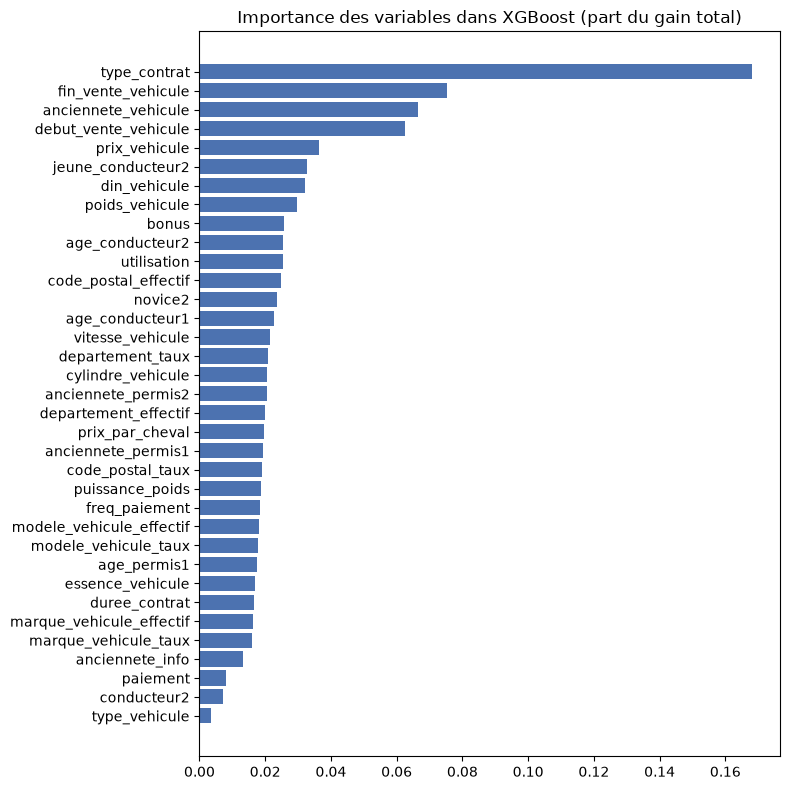

,part du gain
type_contrat,0.168
fin_vente_vehicule,0.075
anciennete_vehicule,0.066
debut_vente_vehicule,0.063
prix_vehicule,0.036
jeune_conducteur2,0.033
din_vehicule,0.032
poids_vehicule,0.030
bonus,0.026
age_conducteur2,0.025


In [6]:
A_complet, B_test = preparer_arbre(train, y, groupes, test)
modeles_finaux = Parallel(n_jobs=6, prefer="threads")(
    delayed(lambda i, g: creer_xgb(*REGLAGES[i], g).fit(A_complet, y))(i, g) for i, g in taches)
p_xgb_test = recalibrer(np.mean([m.predict_proba(B_test)[:, 1] for m in modeles_finaux], axis=0))
p_E_test = pd.read_csv(PREDICTIONS / "frequence_final_test.csv")
assert (p_E_test["id"].values == test["index"].values).all()
p_melange_test = w_melange * p_xgb_test + (1 - w_melange) * p_E_test["proba_pred"].values

for nom, p_oof, p_test in [("xgboost", p_xgb_cal, p_xgb_test), ("melange", p_melange, p_melange_test)]:
    pd.DataFrame({"index": train["index"], "pli": pli, "proba_pred": p_oof}).to_csv(PREDICTIONS / f"frequence_{nom}_oof_train.csv", index=False)
    pd.DataFrame({"id": test["index"], "proba_pred": p_test}).to_csv(PREDICTIONS / f"frequence_{nom}_test.csv", index=False)
    pente = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_oof).reshape(-1, 1), y).coef_[0][0]
    print(f"{nom} : hors pli {p_oof.sum():.0f} sinistres prédits pour {int(y.sum())} observés, pente {pente:.3f} "
          f"| probabilité moyenne sur le test {p_test.mean():.4f}")

importance = pd.DataFrame([m.get_booster().get_score(importance_type="gain") for m in modeles_finaux]).fillna(0).mean()
importance = (importance / importance.sum()).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(importance.index[::-1], importance.values[::-1], color="#4C72B0")
ax.set_title("Importance des variables dans XGBoost (part du gain total)")
plt.tight_layout()
plt.show()
importance.round(3).to_frame("part du gain").head(15)

### Conclusions

> **Meilleur modèle de fréquence : mélange 50 % XGBoost recalibré + 50 % logistique E.**
> XGBoost : 4 réglages × 5 graines (20 modèles), 35 colonnes, recalibration de Platt. Logistique E : 17 variables (notebook 01).

| Fréquence (hors pli, 50 000 contrats) | Log-loss | Gini | Brier | RMSE de la prime |
|---|---|---|---|---|
| Logistique + courbes (binôme, Kaggle 1365.657) | 0,21386 | 0,306 | 0,05406 | 541,927 |
| Logistique E | 0,21357 | 0,311 | 0,05402 | 541,794 |
| XGBoost recalibré | 0,21349 | 0,312 | 0,05402 | 541,637 |
| **Mélange XGBoost + E** | **0,21327** | **0,316** | **0,05399** | **541,614** |

1. **XGBoost seul ne bat pas nettement la logistique** en log-loss : il fait jeu égal. Avec si peu de sinistres, le modèle complexe n'a pas beaucoup plus à apprendre.
2. **Ce qui marche, c'est de combiner** les deux. Ils ne font pas les mêmes erreurs, donc leur moyenne est meilleure que chacun.
3. **La calibration compte pour la prime** : XGBoost brut sous-estimait de 1 % le nombre de sinistres ; recalibré, le total est exact (2 917).
4. **Les variables les plus utilisées par les arbres** sont les mêmes que pour la logistique : type de contrat (17 % du gain), âge du véhicule (trois mesures, environ 20 % au total), puis prix, puissance, poids, jeune 2ᵉ conducteur et bonus.
5. **Les gains restent modestes** : −0,0003 de log-loss et −0,18 de RMSE contre E. Ils sont significatifs pli par pli, mais du même ordre que l'écart entre E et la fréquence du binôme. Or, sur Kaggle, cet écart n'a pas été confirmé (E : 1365.915 contre 1365.657). L'erreur sur la prime dépend surtout de quelques gros sinistres.